In [1]:
"""
STEP 3C: LoLiMoT - LOCAL LINEAR MODEL TREE
==========================================

Implementation of LoLiMoT (Local Linear Model Tree) for prediction of velocity fields
- Information sharing between local models via validity functions.

Approach:
- Manually defined REGIONS based on flow physics (x and z partitioning)
- Train ONE LOCAL LINEAR MODEL per region
- Use VALIDITY FUNCTIONS (Gaussian) to blend predictions
- Smooth transitions between regions

Regions are defined based on flow physics:
- X-direction: Upstream, Cube, Near Wake, Far Wake
- Z-direction: Near-wall, Cube height, Mixing layer, Outer flow

Author: Vit Uhlir
"""

from setup_paths import PROCESSED_DATA_DIR, RESULTS_DIR, FIGURES_DIR, REPORTS_DIR
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.interpolate import interp1d
import warnings
warnings.filterwarnings('ignore')

In [2]:
# ============================================================================
# CONFIGURATION
# ============================================================================

# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data.pkl'
INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_11.pkl'     # Extracted 11 locations
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_21.pkl'     # Extracted 21 locations
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_51.pkl'     # Extracted 51 locations

OUTPUT_DIR = FIGURES_DIR
RESULTS_OUTPUT = REPORTS_DIR / 'step5_lolimot_results.pkl'


# Cube geometry
H_CUBE = 0.015  # meters
X_CUBE_FRONT = 0.075  # meters (x/H = 5.0)
X_CUBE_BACK = 0.090   # meters (x/H = 6.0)

# Random state for reproducibility
RANDOM_STATE = 42

# Plot settings
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10

                    LoLiMoT IMPLEMENTATION

Local Linear Model Tree with Physics-Based Regions
Key: Validity functions enable smooth blending between regions


In [3]:
# ============================================================================
# REGION DEFINITION (PHYSICS-BASED)
# ============================================================================

print(f"\n{'='*80}")
print("DEFINING PHYSICS-BASED REGIONS")
print("="*80)

# X-direction regions (in meters)
X_REGIONS = {
    'upstream':    {'min': 0.000, 'max': 0.065, 'center': 0.030, 'sigma': 0.025},  # x/H: 0-4.3
    'cube':        {'min': 0.065, 'max': 0.095, 'center': 0.080, 'sigma': 0.015},  # x/H: 4.3-6.3
    'near_wake':   {'min': 0.090, 'max': 0.150, 'center': 0.115, 'sigma': 0.030},  # x/H: 6-10
    'far_wake':    {'min': 0.135, 'max': 0.320, 'center': 0.200, 'sigma': 0.060},  # x/H: 9-21
}

# Z-direction regions (in meters)
Z_REGIONS = {
    'near_wall':   {'min': 0.0000, 'max': 0.0075, 'center': 0.00375, 'sigma': 0.004},  # z/H: 0-0.5
    'cube_height': {'min': 0.0060, 'max': 0.0180, 'center': 0.01200, 'sigma': 0.005},  # z/H: 0.4-1.2
    'mixing':      {'min': 0.0150, 'max': 0.0300, 'center': 0.02250, 'sigma': 0.006},  # z/H: 1.0-2.0
    'outer':       {'min': 0.0250, 'max': 0.0500, 'center': 0.03750, 'sigma': 0.010},  # z/H: 1.7-3.3
}

# Create all region combinations
REGIONS = {}
region_id = 0
for x_name, x_params in X_REGIONS.items():
    for z_name, z_params in Z_REGIONS.items():
        region_key = f"{x_name}_{z_name}"
        REGIONS[region_key] = {
            'id': region_id,
            'x_name': x_name,
            'z_name': z_name,
            'x_center': x_params['center'],
            'z_center': z_params['center'],
            'x_sigma': x_params['sigma'],
            'z_sigma': z_params['sigma'],
            'x_min': x_params['min'],
            'x_max': x_params['max'],
            'z_min': z_params['min'],
            'z_max': z_params['max'],
        }
        region_id += 1

N_REGIONS = len(REGIONS)
print(f"\n✓ Created {N_REGIONS} regions ({len(X_REGIONS)} x-regions × {len(Z_REGIONS)} z-regions)")

print(f"\nX-direction regions:")
for name, params in X_REGIONS.items():
    print(f"  {name:12s}: x/H = [{params['min']/H_CUBE:.1f}, {params['max']/H_CUBE:.1f}], "
          f"center = {params['center']/H_CUBE:.1f}, σ = {params['sigma']/H_CUBE:.2f}")

print(f"\nZ-direction regions:")
for name, params in Z_REGIONS.items():
    print(f"  {name:12s}: z/H = [{params['min']/H_CUBE:.1f}, {params['max']/H_CUBE:.1f}], "
          f"center = {params['center']/H_CUBE:.2f}, σ = {params['sigma']/H_CUBE:.2f}")



DEFINING PHYSICS-BASED REGIONS

✓ Created 16 regions (4 x-regions × 4 z-regions)

X-direction regions:
  upstream    : x/H = [0.0, 4.3], center = 2.0, σ = 1.67
  cube        : x/H = [4.3, 6.3], center = 5.3, σ = 1.00
  near_wake   : x/H = [6.0, 10.0], center = 7.7, σ = 2.00
  far_wake    : x/H = [9.0, 21.3], center = 13.3, σ = 4.00

Z-direction regions:
  near_wall   : z/H = [0.0, 0.5], center = 0.25, σ = 0.27
  cube_height : z/H = [0.4, 1.2], center = 0.80, σ = 0.33
  mixing      : z/H = [1.0, 2.0], center = 1.50, σ = 0.40
  outer       : z/H = [1.7, 3.3], center = 2.50, σ = 0.67


In [4]:
# ============================================================================
# VALIDITY FUNCTION
# ============================================================================

def validity_function(x, z, region):
    """
    Gaussian validity function for a region.
    
    φ(x,z) = exp(-((x - x_c)²/σ_x² + (z - z_c)²/σ_z²))
    
    Returns value between 0 and 1 indicating how much this region
    should contribute to the prediction at (x, z).
    """
    x_c = region['x_center']
    z_c = region['z_center']
    sigma_x = region['x_sigma']
    sigma_z = region['z_sigma']
    
    # Gaussian validity
    phi = np.exp(-((x - x_c)**2 / (2 * sigma_x**2) + 
                   (z - z_c)**2 / (2 * sigma_z**2)))
    
    return phi


def compute_all_validities(x, z, regions):
    """
    Compute validity functions for all regions at point (x, z).
    Returns normalized weights that sum to 1.
    """
    validities = {}
    total = 0.0
    
    for region_key, region in regions.items():
        phi = validity_function(x, z, region)
        validities[region_key] = phi
        total += phi
    
    # Normalize so weights sum to 1
    if total > 0:
        for key in validities:
            validities[key] /= total
    
    return validities


# Test validity function
print(f"\n✓ Validity function defined")
test_x, test_z = 0.10, 0.015  # Wake region, cube height
test_validities = compute_all_validities(test_x, test_z, REGIONS)
print(f"\nExample: At x/H={test_x/H_CUBE:.1f}, z/H={test_z/H_CUBE:.1f}")
print(f"  Top 3 contributing regions:")
sorted_v = sorted(test_validities.items(), key=lambda x: x[1], reverse=True)[:3]
for region_key, weight in sorted_v:
    print(f"    {region_key:25s}: {weight:.3f} ({weight*100:.1f}%)")



✓ Validity function defined

Example: At x/H=6.7, z/H=1.0
  Top 3 contributing regions:
    near_wake_cube_height    : 0.339 (33.9%)
    near_wake_mixing         : 0.186 (18.6%)
    cube_cube_height         : 0.158 (15.8%)


In [5]:
# ============================================================================
# LOAD DATA
# ============================================================================

print(f"\n{'='*80}")
print("LOADING DATA")
print("="*80)

with open(INPUT_FILE, 'rb') as f:
    all_cases_data = pickle.load(f)

print(f"✓ Loaded {len(all_cases_data)} cases")

# Extract case parameters
case_parameters = {}
for case_id, case_data in all_cases_data.items():
    case_parameters[case_id] = {
        'U_ref': case_data['U_ref'],
        'profile_type': case_data['profile_type'],
        'profile_name': case_data['profile_name'],
    }



LOADING DATA
✓ Loaded 8 cases


In [6]:
# ============================================================================
# ONE-HOT ENCODING
# ============================================================================

print(f"\n{'='*80}")
print("ONE-HOT ENCODING")
print("="*80)

# Profile type encoding
profile_types_all = np.array([[cp['profile_type']] for cp in case_parameters.values()])
onehot_encoder = OneHotEncoder(sparse_output=False, categories='auto')
onehot_encoder.fit(profile_types_all)

PROFILE_TYPE_MAP = {0: 'Uniform', 1: 'ABL+constant', 2: 'ABL+free', 3: 'ABL+laminar'}
N_PROFILE_TYPES = 4

print(f"✓ Profile type encoder fitted")
for ptype in range(N_PROFILE_TYPES):
    encoding = onehot_encoder.transform([[ptype]])[0]
    print(f"  Type {ptype} ({PROFILE_TYPE_MAP[ptype]:12s}): {encoding}")

# Feature names (without x_norm and z_norm - these are used for validity, not model input)
# Local models use: U_ref + profile_type (one-hot)
FEATURE_NAMES = ['U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']
N_FEATURES = len(FEATURE_NAMES)

print(f"\n✓ Local model features: {FEATURE_NAMES}")
print(f"  (x and z determine WHICH models contribute, not model inputs)")



ONE-HOT ENCODING
✓ Profile type encoder fitted
  Type 0 (Uniform     ): [1. 0. 0. 0.]
  Type 1 (ABL+constant): [0. 1. 0. 0.]
  Type 2 (ABL+free    ): [0. 0. 1. 0.]
  Type 3 (ABL+laminar ): [0. 0. 0. 1.]

✓ Local model features: ['U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']
  (x and z determine WHICH models contribute, not model inputs)


In [7]:
# ============================================================================
# AUTOMATIC TRAIN/TEST SPLIT
# ============================================================================

print(f"\n{'='*80}")
print("TRAIN/TEST SPLIT BY FLOW REGIME")
print("="*80)

# Get all x-locations
all_x_locations = sorted(list(set([x for case_data in all_cases_data.values() 
                                     for x in case_data['profiles'].keys()])))

print(f"\nAvailable x-locations: {len(all_x_locations)}")
print(f"  x/H: {[f'{x/H_CUBE:.1f}' for x in all_x_locations]}")

# Categorize by flow regime
X_RECOVERY = 0.14  # Start of far downstream

regime_locations = {
    'upstream': [],
    'over_cube': [],
    'wake': [],
    'far_downstream': []
}

for x in all_x_locations:
    if x < X_CUBE_FRONT:
        regime_locations['upstream'].append(x)
    elif x <= X_CUBE_BACK:
        regime_locations['over_cube'].append(x)
    elif x < X_RECOVERY:
        regime_locations['wake'].append(x)
    else:
        regime_locations['far_downstream'].append(x)

print(f"\n📍 Locations by flow regime:")
for regime, locs in regime_locations.items():
    x_H = [f'{x/H_CUBE:.1f}' for x in locs]
    print(f"  {regime:15s}: {len(locs):2d} locations  (x/H: {x_H})")

# Select test locations: middle of each regime
x_test = []
for regime, locs in regime_locations.items():
    if len(locs) >= 2:
        mid_idx = len(locs) // 2
        x_test.append(locs[mid_idx])
    elif len(locs) == 1:
        print(f"  ⚠️  {regime}: Only 1 location, keeping for training")

x_train = [x for x in all_x_locations if x not in x_test]
x_train = sorted(x_train)
x_test = sorted(x_test)

print(f"\n✓ Training: {len(x_train)} x-locations")
print(f"  x/H: {[f'{x/H_CUBE:.1f}' for x in x_train]}")
print(f"\n✓ Testing: {len(x_test)} x-locations (one per regime)")
print(f"  x/H: {[f'{x/H_CUBE:.1f}' for x in x_test]}")



TRAIN/TEST SPLIT BY FLOW REGIME

Available x-locations: 11
  x/H: ['0.0', '2.5', '4.3', '5.0', '5.5', '6.0', '7.0', '8.0', '9.0', '10.0', '21.0']

📍 Locations by flow regime:
  upstream       :  3 locations  (x/H: ['0.0', '2.5', '4.3'])
  over_cube      :  2 locations  (x/H: ['5.0', '5.5'])
  wake           :  4 locations  (x/H: ['6.0', '7.0', '8.0', '9.0'])
  far_downstream :  2 locations  (x/H: ['10.0', '21.0'])

✓ Training: 7 x-locations
  x/H: ['0.0', '4.3', '5.0', '6.0', '7.0', '9.0', '10.0']

✓ Testing: 4 x-locations (one per regime)
  x/H: ['2.5', '5.5', '8.0', '21.0']


In [8]:
# ============================================================================
# EXTRACT TRAINING DATA FOR EACH REGION
# ============================================================================

print(f"\n{'='*80}")
print("EXTRACTING TRAINING DATA BY REGION")
print("="*80)

# Collect ALL training data points
all_training_points = []

for case_id, case_data in all_cases_data.items():
    params = case_parameters[case_id]
    
    for x_loc in x_train:
        if x_loc in case_data['profiles']:
            profile = case_data['profiles'][x_loc]
            z_vals = profile['z']
            U_vals = profile['U_x']
            
            for z_val, U_val in zip(z_vals, U_vals):
                # Create feature vector (without x, z - those determine validity)
                profile_onehot = onehot_encoder.transform([[params['profile_type']]])[0]
                features = np.concatenate([[params['U_ref']], profile_onehot])
                
                all_training_points.append({
                    'x': x_loc,
                    'z': z_val,
                    'U_ref': params['U_ref'],
                    'profile_type': params['profile_type'],
                    'features': features,
                    'U_x': U_val
                })

print(f"✓ Total training points: {len(all_training_points)}")

# Convert to arrays for efficiency
X_all = np.array([p['features'] for p in all_training_points])
y_all = np.array([p['U_x'] for p in all_training_points])
x_coords = np.array([p['x'] for p in all_training_points])
z_coords = np.array([p['z'] for p in all_training_points])

print(f"  Feature matrix shape: {X_all.shape}")
print(f"  Target shape: {y_all.shape}")


EXTRACTING TRAINING DATA BY REGION
✓ Total training points: 3288
  Feature matrix shape: (3288, 5)
  Target shape: (3288,)


In [11]:
# ============================================================================
# TRAIN LOCAL LINEAR MODELS FOR EACH REGION
# ============================================================================

print(f"\n{'='*80}")
print("TRAINING LOCAL LINEAR MODELS")
print("="*80)

# Feature scaler (fitted on all data)
feature_scaler = StandardScaler()
feature_scaler.fit(X_all)
X_all_scaled = feature_scaler.transform(X_all)

print(f"\n✓ Feature scaler fitted")
print(f"  Means: {feature_scaler.mean_}")
print(f"  Stds:  {feature_scaler.scale_}")

# Train one model per region using WEIGHTED regression
region_models = {}
region_metrics = {}

for region_key, region in REGIONS.items():
    # Compute validity weights for all training points
    weights = np.array([validity_function(x, z, region) 
                        for x, z in zip(x_coords, z_coords)])
    
    # Only use points with non-negligible weight
    weight_threshold = 0.01
    valid_mask = weights > weight_threshold
    n_valid = valid_mask.sum()
    
    if n_valid < 10:
        print(f"  ⚠️  {region_key}: Only {n_valid} points, skipping")
        continue
    
    X_region = X_all_scaled[valid_mask]
    y_region = y_all[valid_mask]
    w_region = weights[valid_mask]
    
    # Normalize weights
    w_region = w_region / w_region.sum() * len(w_region)
    
    # Train weighted linear regression (Ridge for regularization)
    model = Ridge(alpha=0.1)
    model.fit(X_region, y_region, sample_weight=w_region)
    
    # Evaluate on weighted training data
    y_pred = model.predict(X_region)
    
    # Weighted R² and RMSE
    ss_res = np.sum(w_region * (y_region - y_pred)**2)
    ss_tot = np.sum(w_region * (y_region - np.average(y_region, weights=w_region))**2)
    R2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0
    RMSE = np.sqrt(np.average((y_region - y_pred)**2, weights=w_region))
    
    region_models[region_key] = model
    region_metrics[region_key] = {
        'R2': R2,
        'RMSE': RMSE,
        'n_points': n_valid,
        'sum_weights': weights.sum(),
        'coef': model.coef_,
        'intercept': model.intercept_
    }

print(f"\n✓ Trained {len(region_models)} regional models")

# Summary table
print(f"\n{'Region':<30s} {'Points':>8s} {'R²':>8s} {'RMSE':>10s}")
print("-" * 60)
for region_key in sorted(region_models.keys()):
    m = region_metrics[region_key]
    print(f"{region_key:<30s} {m['n_points']:>8d} {m['R2']:>8.3f} {m['RMSE']:>10.4f}")



TRAINING LOCAL LINEAR MODELS

✓ Feature scaler fitted
  Means: [3.05 0.25 0.25 0.25 0.25]
  Stds:  [2.05      0.4330127 0.4330127 0.4330127 0.4330127]

✓ Trained 16 regional models

Region                           Points       R²       RMSE
------------------------------------------------------------
cube_cube_height                   1352    0.126     1.4727
cube_mixing                        1448    0.537     1.4670
cube_near_wall                      768    0.019     1.2291
cube_outer                         1504    0.869     0.7994
far_wake_cube_height               1760    0.128     1.0502
far_wake_mixing                    1848    0.504     1.3780
far_wake_near_wall                 1056    0.008     0.8987
far_wake_outer                     1888    0.878     0.7649
near_wake_cube_height              1912    0.052     1.2032
near_wake_mixing                   2048    0.431     1.5726
near_wake_near_wall                1152    0.020     1.0213
near_wake_outer                    2

In [12]:
# ============================================================================
# LOLIMOT PREDICTION FUNCTION
# ============================================================================

def lolimot_predict(x, z, U_ref, profile_type, 
                    region_models, regions, feature_scaler, onehot_encoder):
    """
    LoLiMoT prediction: weighted combination of local linear models.
    
    U(x,z) = Σᵢ φᵢ(x,z) · modelᵢ(features) / Σᵢ φᵢ(x,z)
    
    where φᵢ is the validity function for region i.
    """
    # Create feature vector
    profile_onehot = onehot_encoder.transform([[profile_type]])[0]
    features = np.concatenate([[U_ref], profile_onehot]).reshape(1, -1)
    features_scaled = feature_scaler.transform(features)
    
    # Compute validity weights
    validities = compute_all_validities(x, z, regions)
    
    # Weighted prediction
    U_pred = 0.0
    total_weight = 0.0
    
    for region_key, weight in validities.items():
        if region_key in region_models and weight > 1e-6:
            model = region_models[region_key]
            pred = model.predict(features_scaled)[0]
            U_pred += weight * pred
            total_weight += weight
    
    if total_weight > 0:
        U_pred /= total_weight
    
    return U_pred, validities


# Test prediction
print(f"\n✓ LoLiMoT prediction function defined")
test_pred, test_weights = lolimot_predict(
    x=0.10, z=0.015, U_ref=3.0, profile_type=2,
    region_models=region_models, regions=REGIONS,
    feature_scaler=feature_scaler, onehot_encoder=onehot_encoder
)
print(f"\nTest prediction at x/H=6.7, z/H=1.0, U_ref=3.0, type=ABL+free:")
print(f"  U_pred = {test_pred:.3f} m/s")


✓ LoLiMoT prediction function defined

Test prediction at x/H=6.7, z/H=1.0, U_ref=3.0, type=ABL+free:
  U_pred = 1.217 m/s


In [13]:
# ============================================================================
# SPATIAL TEST
# ============================================================================

print(f"\n{'='*80}")
print("SPATIAL INTERPOLATION TEST")
print("="*80)

spatial_results = []

for case_id, case_data in all_cases_data.items():
    params = case_parameters[case_id]
    
    for x_loc in x_test:
        if x_loc in case_data['profiles']:
            profile = case_data['profiles'][x_loc]
            z_vals = profile['z']
            U_true = profile['U_x']
            
            U_pred = []
            for z_val in z_vals:
                pred, _ = lolimot_predict(
                    x=x_loc, z=z_val, 
                    U_ref=params['U_ref'], profile_type=params['profile_type'],
                    region_models=region_models, regions=REGIONS,
                    feature_scaler=feature_scaler, onehot_encoder=onehot_encoder
                )
                U_pred.append(pred)
            
            U_pred = np.array(U_pred)
            
            # Metrics
            R2 = r2_score(U_true, U_pred)
            RMSE = np.sqrt(mean_squared_error(U_true, U_pred))
            MAE = mean_absolute_error(U_true, U_pred)
            
            spatial_results.append({
                'case_id': case_id,
                'x': x_loc,
                'x_norm': x_loc / H_CUBE,
                'U_ref': params['U_ref'],
                'profile_type': params['profile_type'],
                'R2': R2,
                'RMSE': RMSE,
                'MAE': MAE,
                'U_true': U_true,
                'U_pred': U_pred,
                'z': z_vals
            })

# Summary by x-location
print(f"\nSpatial test results by x-location:")
print(f"{'x/H':>8s} {'Avg R²':>10s} {'Avg RMSE':>12s}")
print("-" * 35)

for x_loc in x_test:
    results_at_x = [r for r in spatial_results if r['x'] == x_loc]
    avg_R2 = np.mean([r['R2'] for r in results_at_x])
    avg_RMSE = np.mean([r['RMSE'] for r in results_at_x])
    print(f"{x_loc/H_CUBE:>8.1f} {avg_R2:>10.3f} {avg_RMSE:>12.4f}")

# Overall
overall_R2 = np.mean([r['R2'] for r in spatial_results])
overall_RMSE = np.mean([r['RMSE'] for r in spatial_results])
print("-" * 35)
print(f"{'Overall':>8s} {overall_R2:>10.3f} {overall_RMSE:>12.4f}")



SPATIAL INTERPOLATION TEST

Spatial test results by x-location:
     x/H     Avg R²     Avg RMSE
-----------------------------------
     2.5     -0.974       0.5766
     5.5      0.432       0.9578
     8.0      0.749       0.9199
    21.0     -1.985       1.0906
-----------------------------------
 Overall     -0.445       0.8862



CREATING VISUALIZATIONS


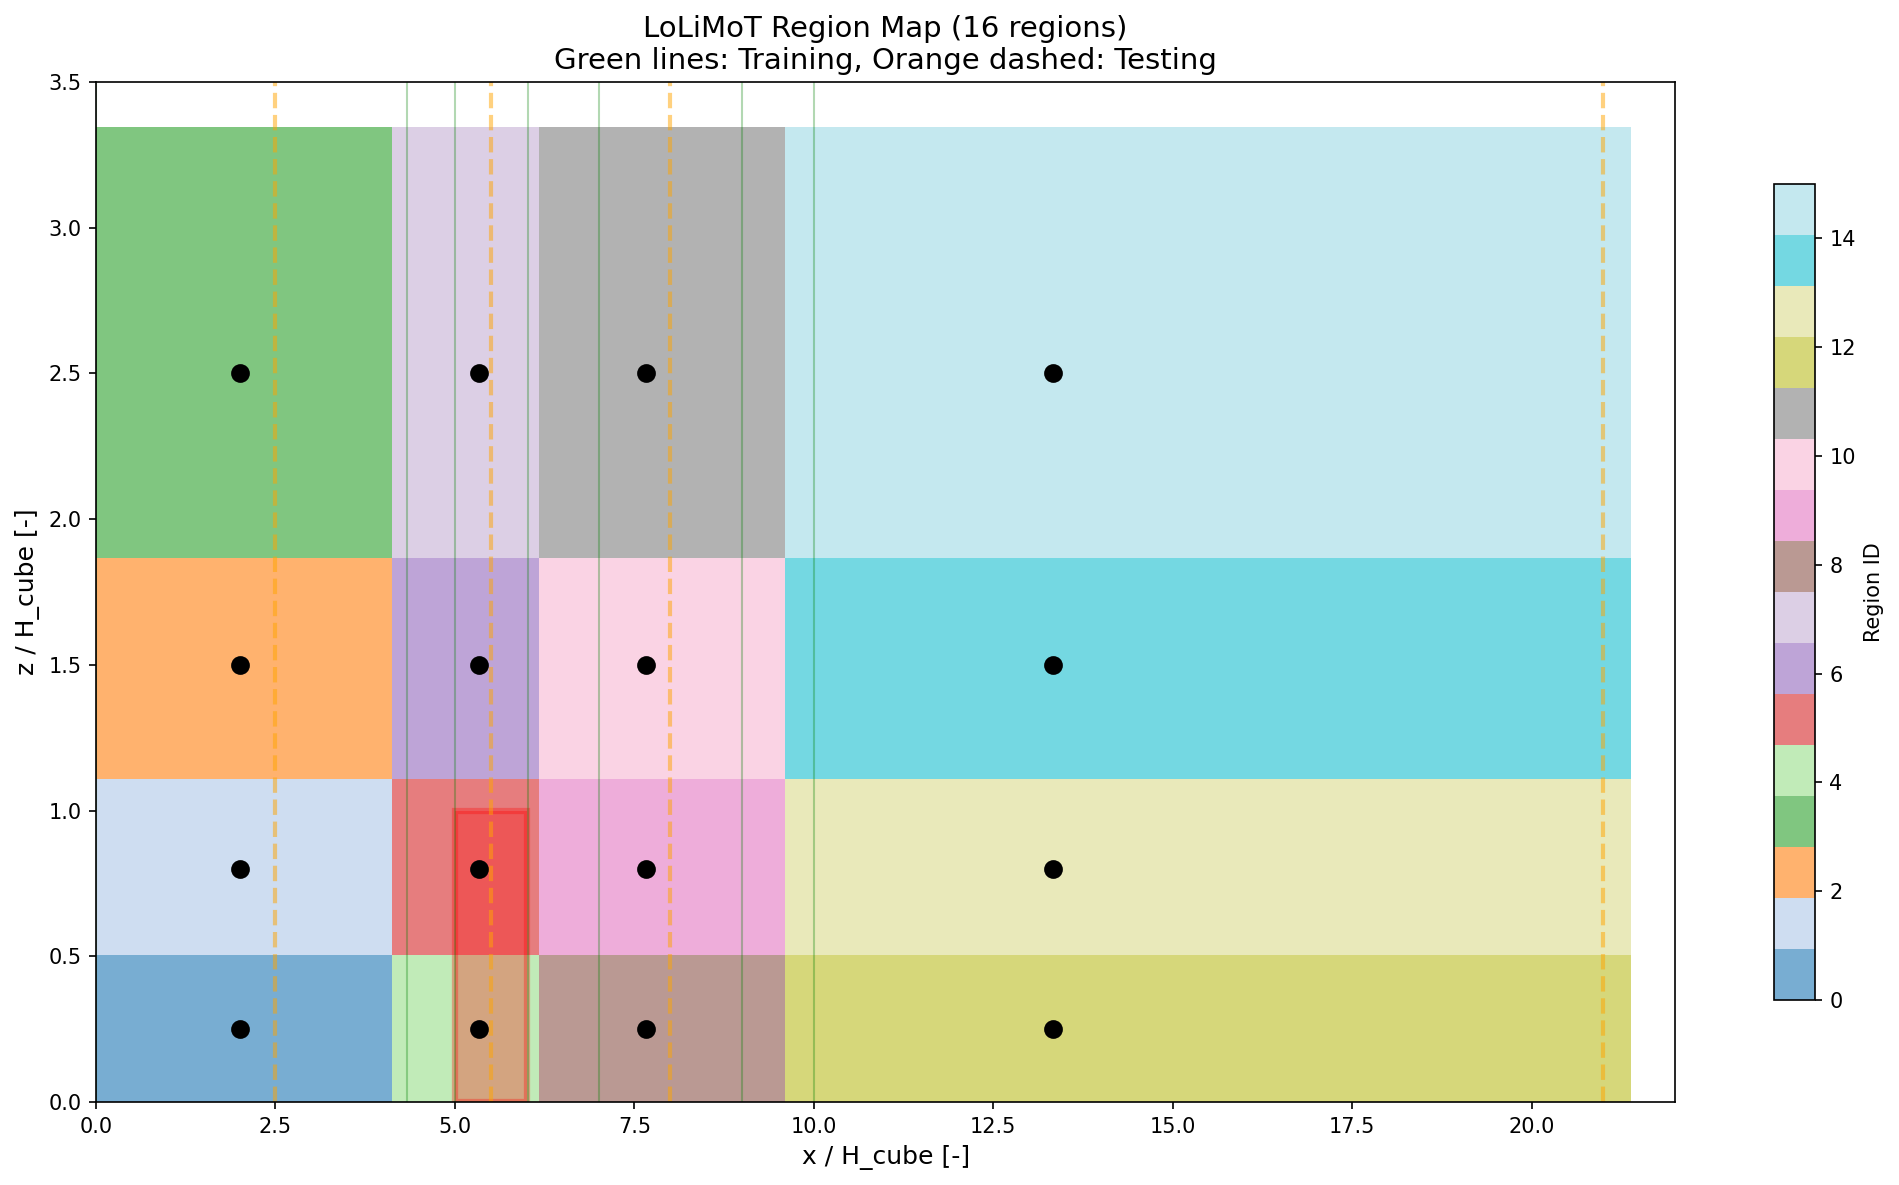

✓ Saved: step5_region_map.png


In [16]:
# ============================================================================
# VISUALIZATION 1: REGION MAP
# ============================================================================

print(f"\n{'='*80}")
print("CREATING VISUALIZATIONS")
print("="*80)

fig, ax = plt.subplots(figsize=(14, 8))

# Create grid for validity visualization
x_grid = np.linspace(0, 0.32, 200)
z_grid = np.linspace(0, 0.05, 150)
X_grid, Z_grid = np.meshgrid(x_grid, z_grid)

# For each point, find dominant region
dominant_region = np.zeros_like(X_grid)
for i in range(X_grid.shape[0]):
    for j in range(X_grid.shape[1]):
        validities = compute_all_validities(X_grid[i,j], Z_grid[i,j], REGIONS)
        max_region = max(validities.items(), key=lambda x: x[1])
        # Map region to color index
        region_idx = list(REGIONS.keys()).index(max_region[0])
        dominant_region[i,j] = region_idx

# Plot with discrete colormap
cmap = plt.cm.get_cmap('tab20', N_REGIONS)
im = ax.pcolormesh(X_grid/H_CUBE, Z_grid/H_CUBE, dominant_region, 
                   cmap=cmap, alpha=0.6, shading='auto')

# Draw region centers
for region_key, region in REGIONS.items():
    ax.plot(region['x_center']/H_CUBE, region['z_center']/H_CUBE, 
            'ko', markersize=8)
    
# Draw cube
cube_rect = Rectangle((X_CUBE_FRONT/H_CUBE, 0), H_CUBE/H_CUBE, 1.0,
                       linewidth=3, edgecolor='red', facecolor='red', alpha=0.3)
ax.add_patch(cube_rect)

# Mark training and test locations
for x in x_train:
    ax.axvline(x/H_CUBE, color='green', alpha=0.3, linewidth=1)
for x in x_test:
    ax.axvline(x/H_CUBE, color='orange', alpha=0.5, linewidth=2, linestyle='--')

ax.set_xlabel('x / H_cube [-]', fontsize=12)
ax.set_ylabel('z / H_cube [-]', fontsize=12)
ax.set_title(f'LoLiMoT Region Map ({N_REGIONS} regions)\n'
             f'Green lines: Training, Orange dashed: Testing', fontsize=14)
ax.set_xlim([0, 22])
ax.set_ylim([0, 3.5])

plt.colorbar(im, ax=ax, label='Region ID', shrink=0.8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step5_region_map.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step5_region_map.png")
plt.close()

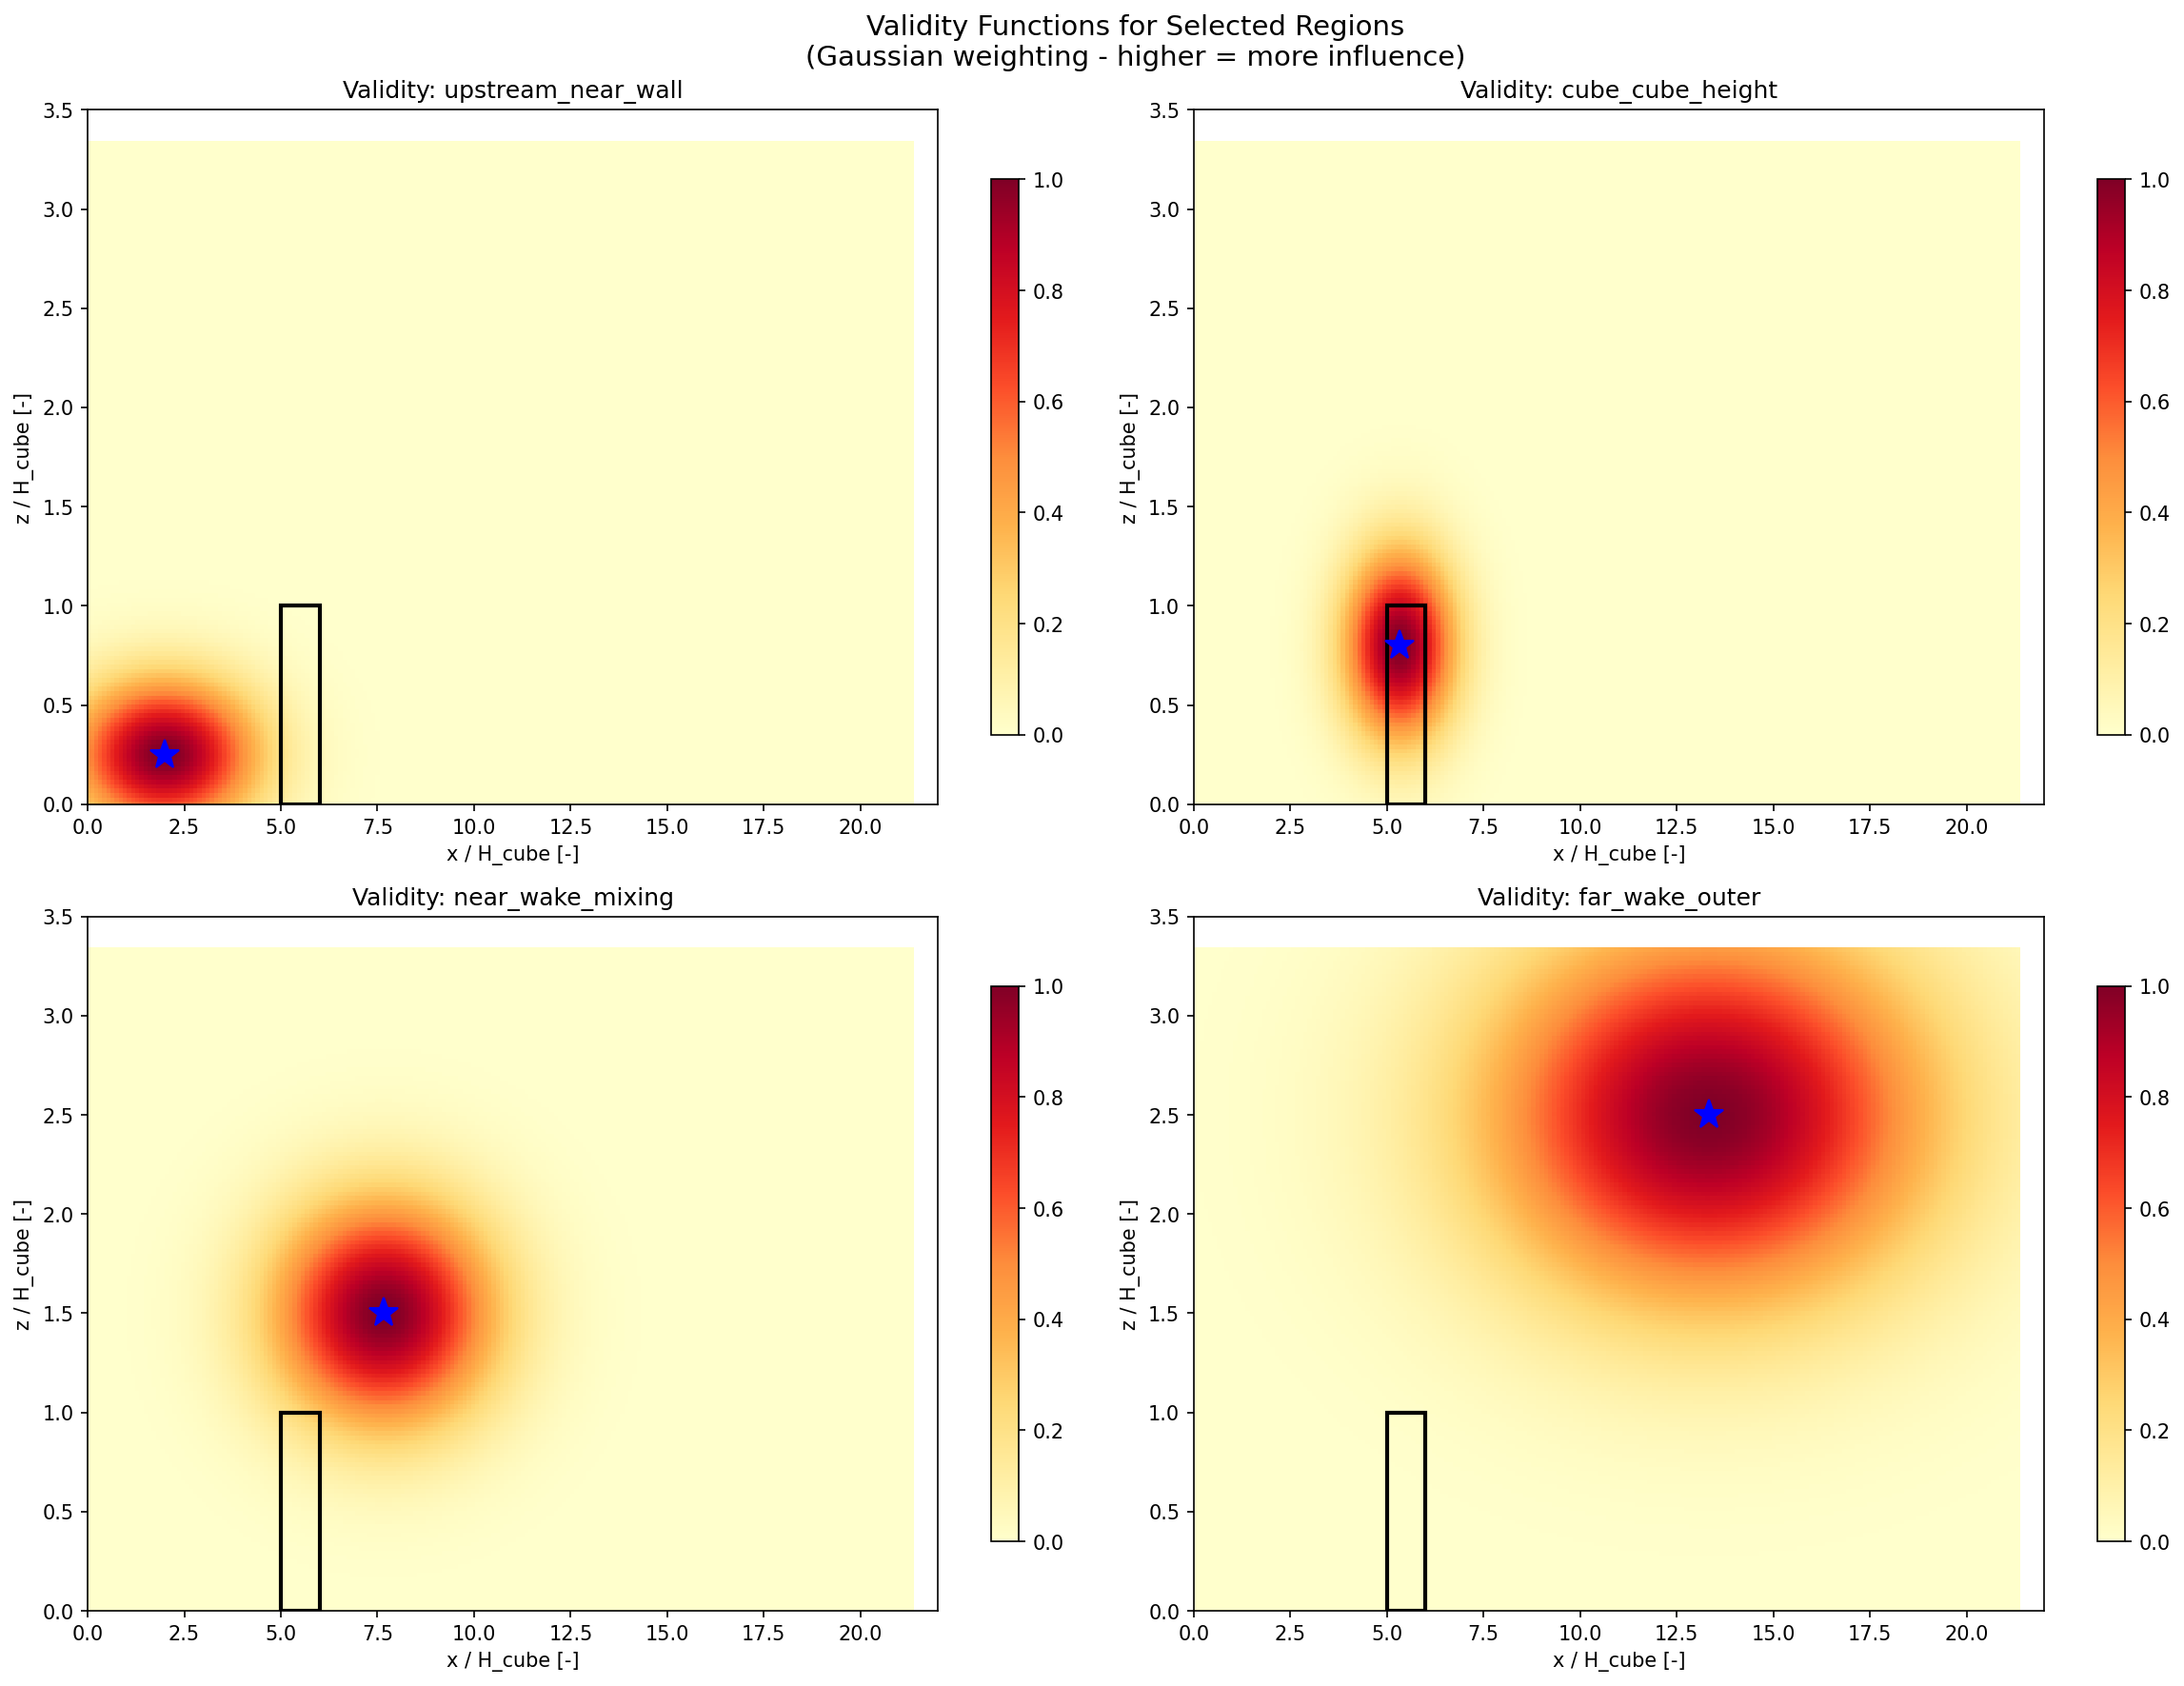

✓ Saved: step5_validity_functions.png


In [18]:
# ============================================================================
# VISUALIZATION 2: VALIDITY FUNCTION EXAMPLE
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Select 4 representative regions to show
show_regions = ['upstream_near_wall', 'cube_cube_height', 
                'near_wake_mixing', 'far_wake_outer']

for ax, region_key in zip(axes.flat, show_regions):
    if region_key not in REGIONS:
        continue
    
    region = REGIONS[region_key]
    
    # Compute validity over grid
    validity_grid = np.zeros_like(X_grid)
    for i in range(X_grid.shape[0]):
        for j in range(X_grid.shape[1]):
            validity_grid[i,j] = validity_function(X_grid[i,j], Z_grid[i,j], region)
    
    im = ax.pcolormesh(X_grid/H_CUBE, Z_grid/H_CUBE, validity_grid,
                       cmap='YlOrRd', vmin=0, vmax=1, shading='auto')
    
    # Mark center
    ax.plot(region['x_center']/H_CUBE, region['z_center']/H_CUBE,
            'b*', markersize=15, label='Center')
    
    # Draw cube
    cube_rect = Rectangle((X_CUBE_FRONT/H_CUBE, 0), 1.0, 1.0,
                          linewidth=2, edgecolor='black', facecolor='none')
    ax.add_patch(cube_rect)
    
    ax.set_xlabel('x / H_cube [-]')
    ax.set_ylabel('z / H_cube [-]')
    ax.set_title(f'Validity: {region_key}')
    ax.set_xlim([0, 22])
    ax.set_ylim([0, 3.5])
    plt.colorbar(im, ax=ax, shrink=0.8)

plt.suptitle('Validity Functions for Selected Regions\n'
             '(Gaussian weighting - higher = more influence)', fontsize=14)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step5_validity_functions.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step5_validity_functions.png")
plt.close()

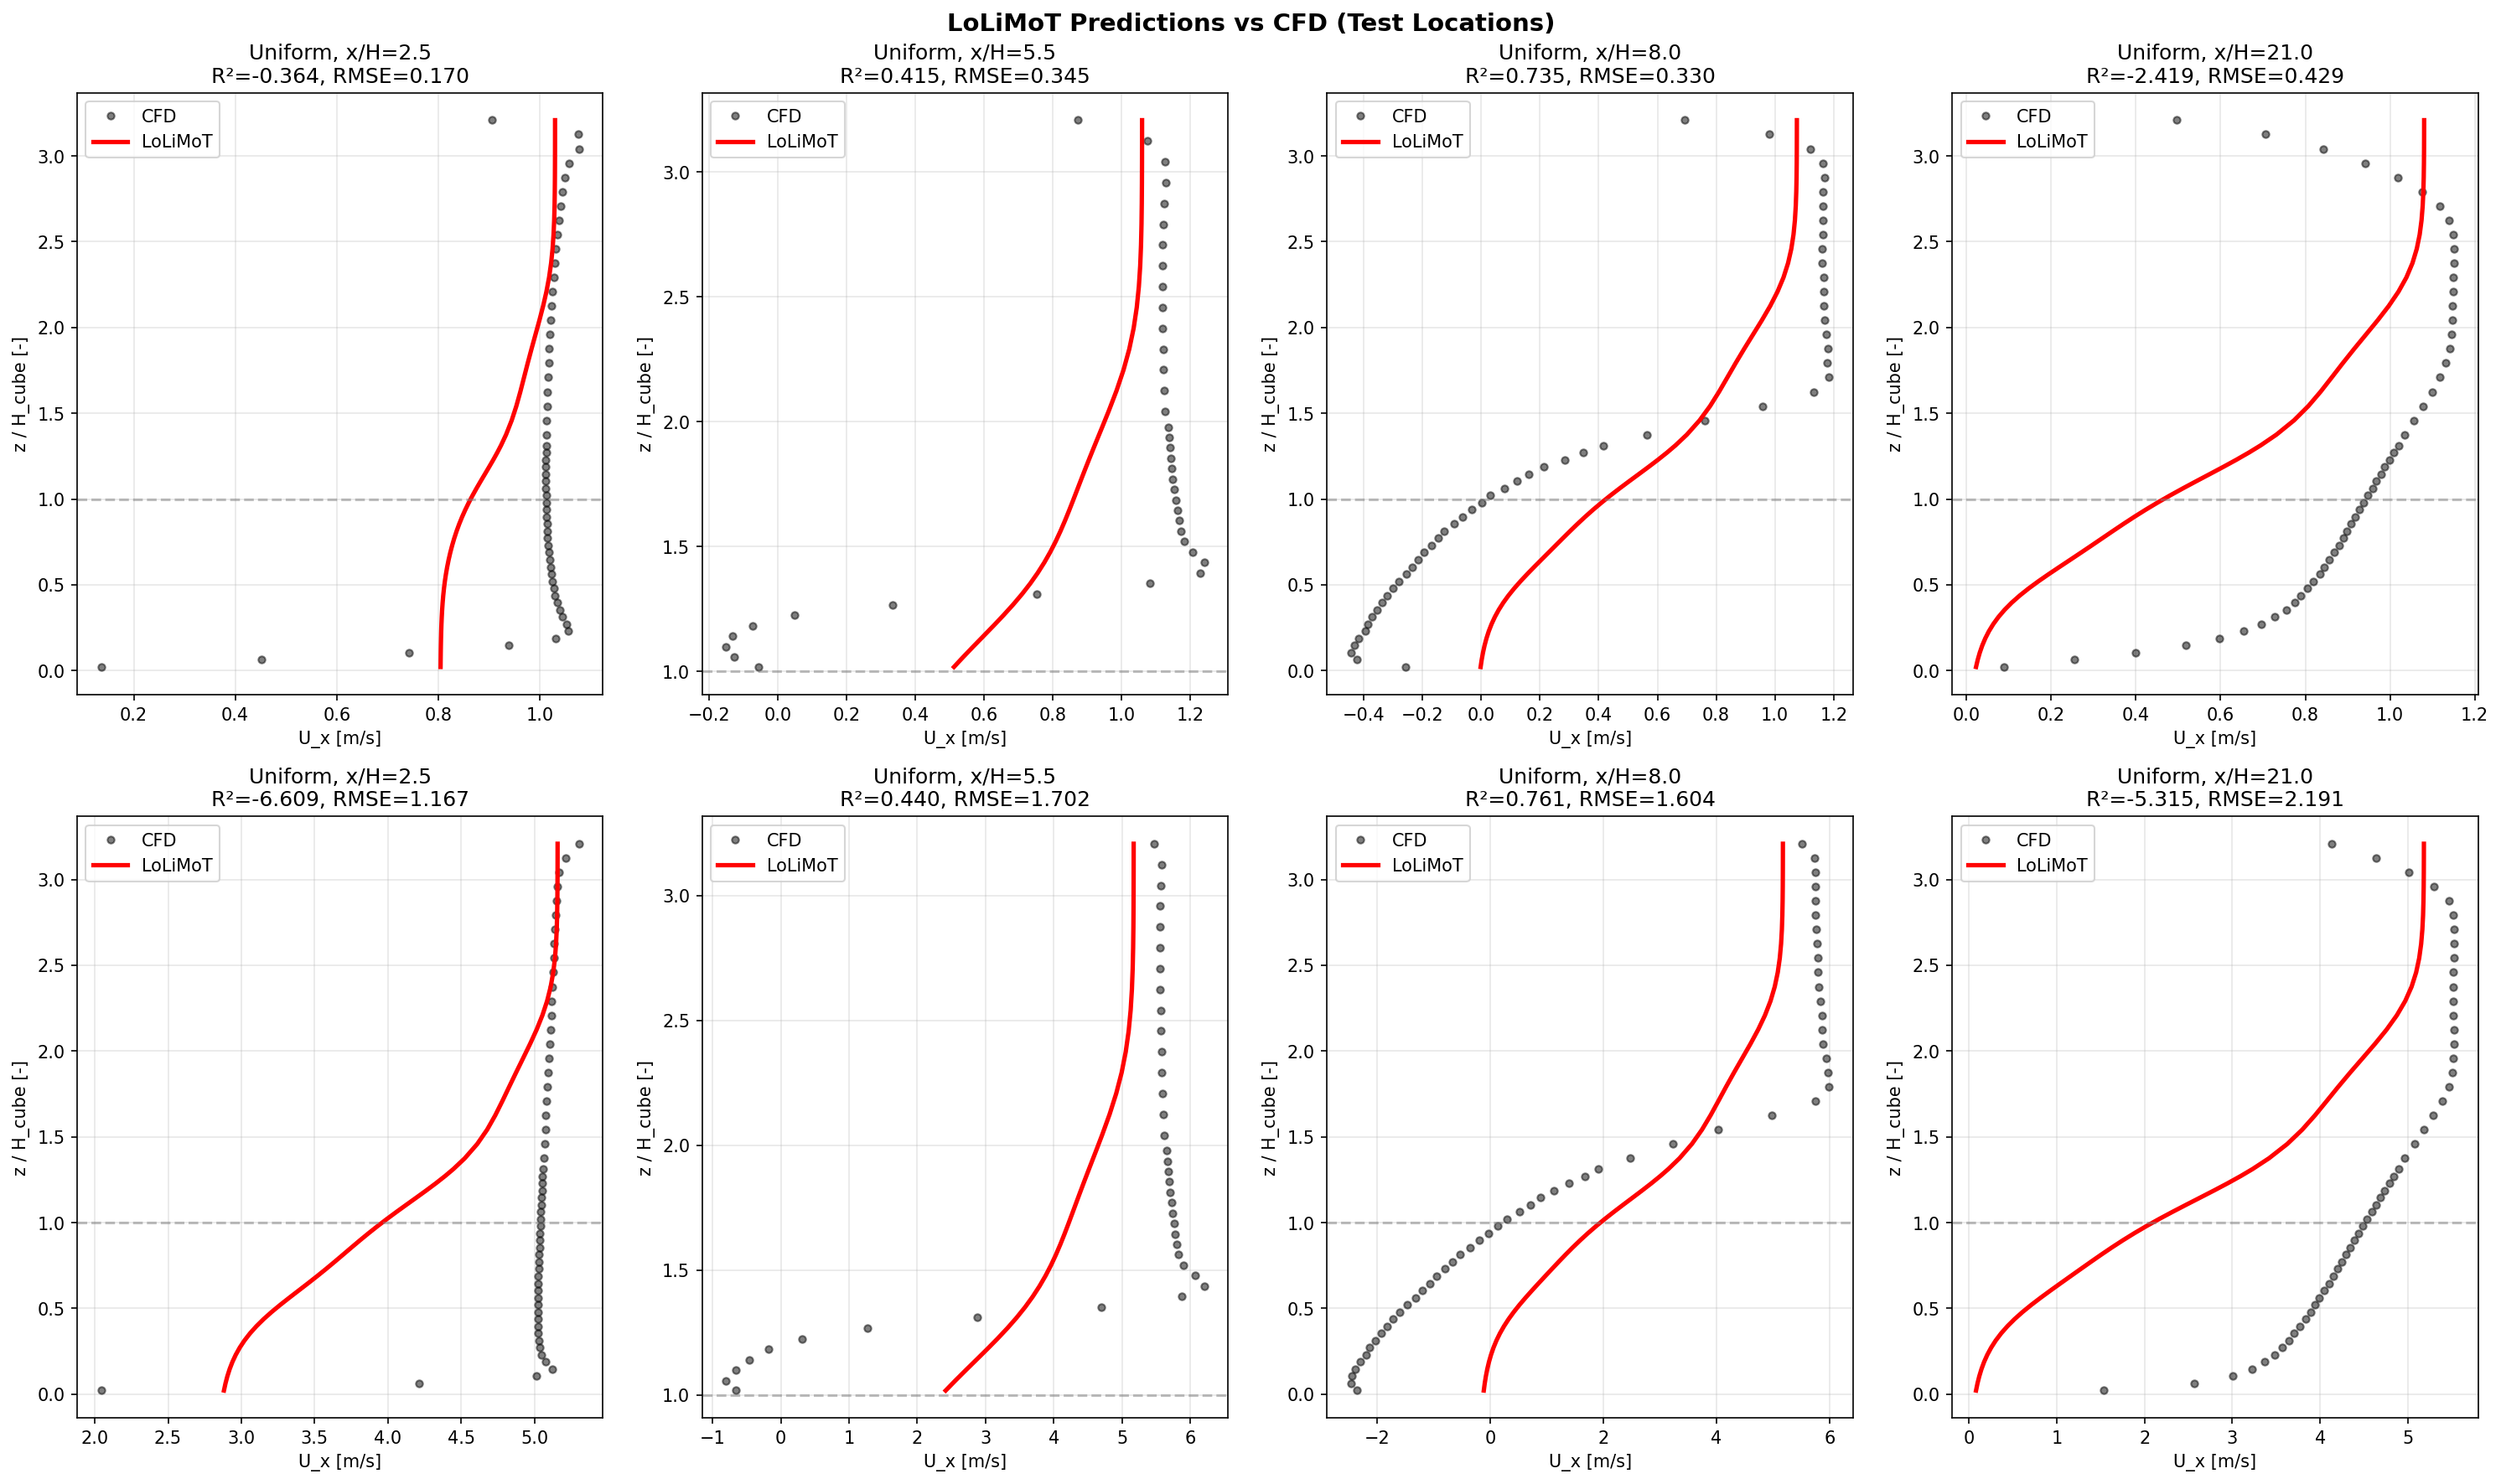

✓ Saved: step5_profile_predictions.png


In [21]:
# ============================================================================
# VISUALIZATION 3: PROFILE PREDICTIONS VS CFD
# ============================================================================

fig, axes = plt.subplots(2, len(x_test), figsize=(5*len(x_test), 12))

# Select two cases for visualization
test_cases = [list(all_cases_data.keys())[0], list(all_cases_data.keys())[4]]

for row, case_id in enumerate(test_cases):
    case_data = all_cases_data[case_id]
    params = case_parameters[case_id]
    
    for col, x_loc in enumerate(x_test):
        ax = axes[row, col] if len(x_test) > 1 else axes[row]
        
        if x_loc in case_data['profiles']:
            profile = case_data['profiles'][x_loc]
            z_cfd = profile['z']
            U_cfd = profile['U_x']
            
            # LoLiMoT prediction
            U_lolimot = []
            for z_val in z_cfd:
                pred, _ = lolimot_predict(
                    x=x_loc, z=z_val,
                    U_ref=params['U_ref'], profile_type=params['profile_type'],
                    region_models=region_models, regions=REGIONS,
                    feature_scaler=feature_scaler, onehot_encoder=onehot_encoder
                )
                U_lolimot.append(pred)
            U_lolimot = np.array(U_lolimot)
            
            # Plot
            ax.plot(U_cfd, z_cfd/H_CUBE, 'ko', markersize=4, alpha=0.5, label='CFD')
            ax.plot(U_lolimot, z_cfd/H_CUBE, 'r-', linewidth=2.5, label='LoLiMoT')
            
            # Metrics
            R2 = r2_score(U_cfd, U_lolimot)
            RMSE = np.sqrt(mean_squared_error(U_cfd, U_lolimot))
            
            ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
            ax.set_xlabel('U_x [m/s]')
            ax.set_ylabel('z / H_cube [-]')
            ax.set_title(f'{case_data["profile_name"]}, x/H={x_loc/H_CUBE:.1f}\n'
                        f'R²={R2:.3f}, RMSE={RMSE:.3f}')
            ax.legend(loc='best')
            ax.grid(True, alpha=0.3)

plt.suptitle('LoLiMoT Predictions vs CFD (Test Locations)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step5_profile_predictions.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step5_profile_predictions.png")
plt.close()

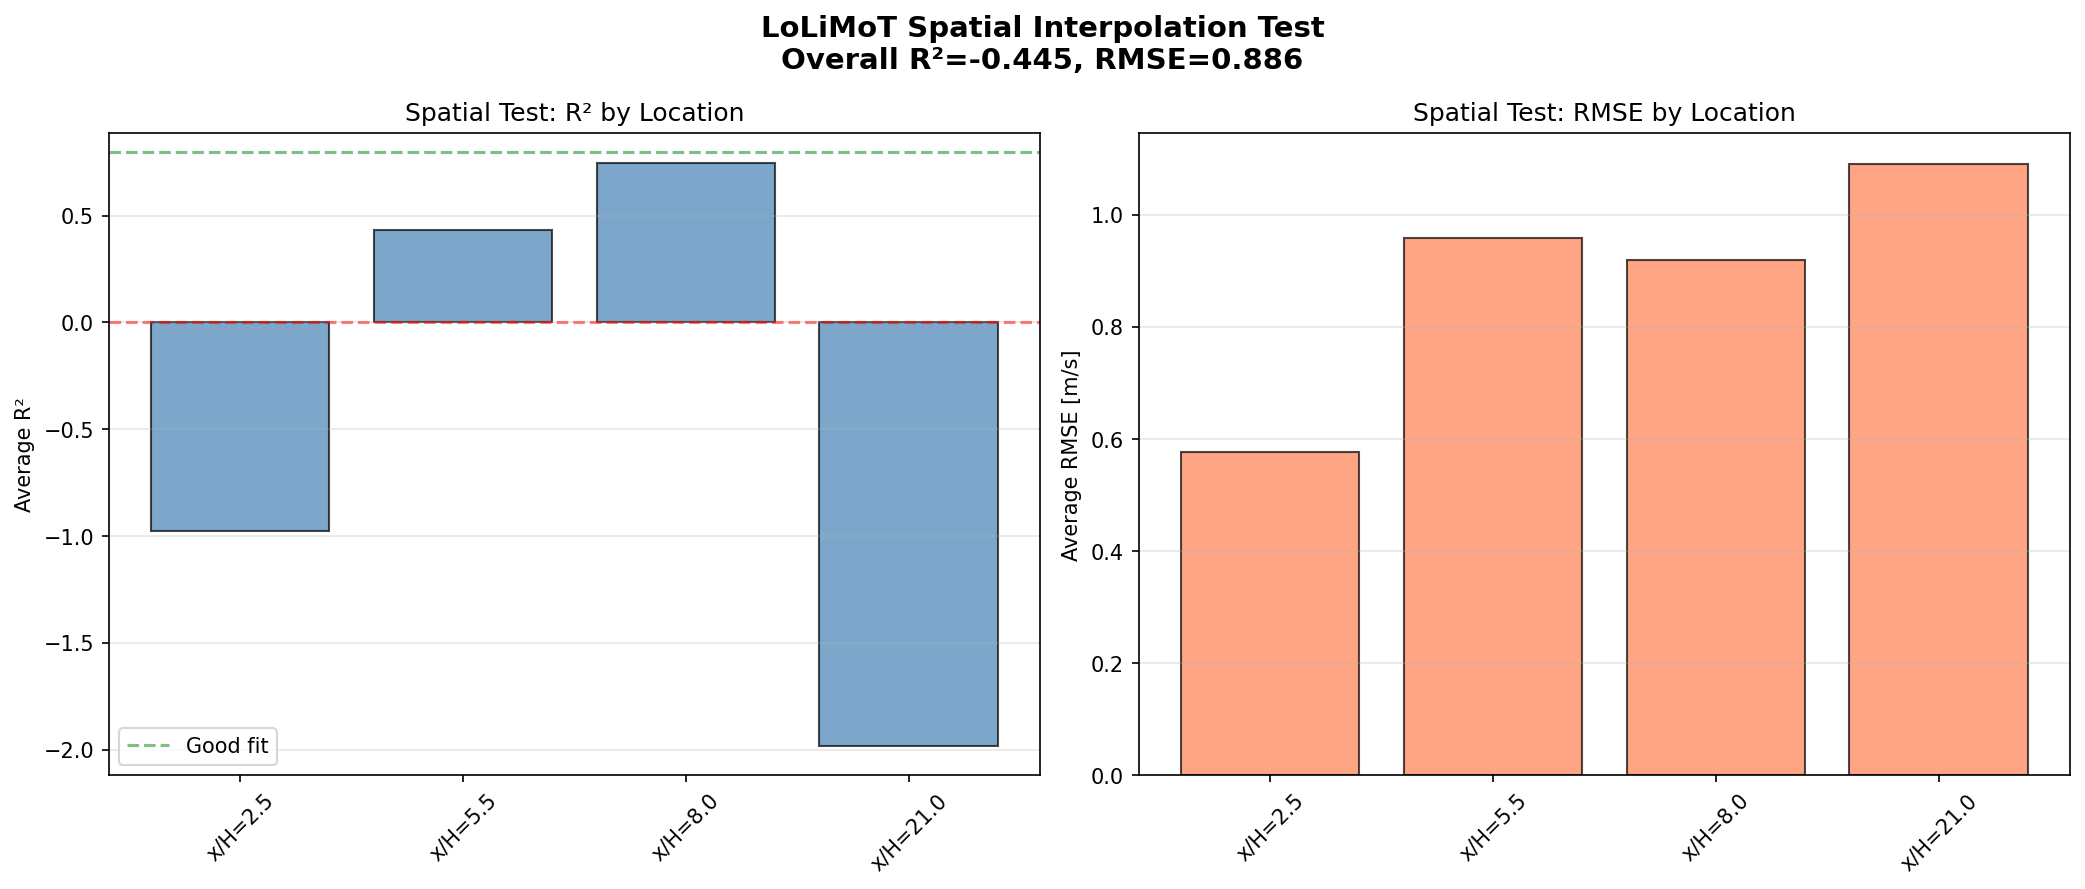

✓ Saved: step5_spatial_test.png


In [22]:
# ============================================================================
# VISUALIZATION 4: SPATIAL TEST RESULTS
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# R² by x-location
ax = axes[0]
x_locs_plot = []
R2_plot = []
for x_loc in x_test:
    results_at_x = [r for r in spatial_results if r['x'] == x_loc]
    avg_R2 = np.mean([r['R2'] for r in results_at_x])
    x_locs_plot.append(x_loc/H_CUBE)
    R2_plot.append(avg_R2)

ax.bar(range(len(x_test)), R2_plot, color='steelblue', alpha=0.7, edgecolor='black')
ax.set_xticks(range(len(x_test)))
ax.set_xticklabels([f'x/H={x:.1f}' for x in x_locs_plot], rotation=45)
ax.set_ylabel('Average R²')
ax.set_title('Spatial Test: R² by Location')
ax.axhline(0, color='red', linestyle='--', alpha=0.5)
ax.axhline(0.8, color='green', linestyle='--', alpha=0.5, label='Good fit')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# RMSE by x-location
ax = axes[1]
RMSE_plot = []
for x_loc in x_test:
    results_at_x = [r for r in spatial_results if r['x'] == x_loc]
    avg_RMSE = np.mean([r['RMSE'] for r in results_at_x])
    RMSE_plot.append(avg_RMSE)

ax.bar(range(len(x_test)), RMSE_plot, color='coral', alpha=0.7, edgecolor='black')
ax.set_xticks(range(len(x_test)))
ax.set_xticklabels([f'x/H={x:.1f}' for x in x_locs_plot], rotation=45)
ax.set_ylabel('Average RMSE [m/s]')
ax.set_title('Spatial Test: RMSE by Location')
ax.grid(True, alpha=0.3, axis='y')

plt.suptitle(f'LoLiMoT Spatial Interpolation Test\n'
             f'Overall R²={overall_R2:.3f}, RMSE={overall_RMSE:.3f}', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step5_spatial_test.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step5_spatial_test.png")
plt.close()

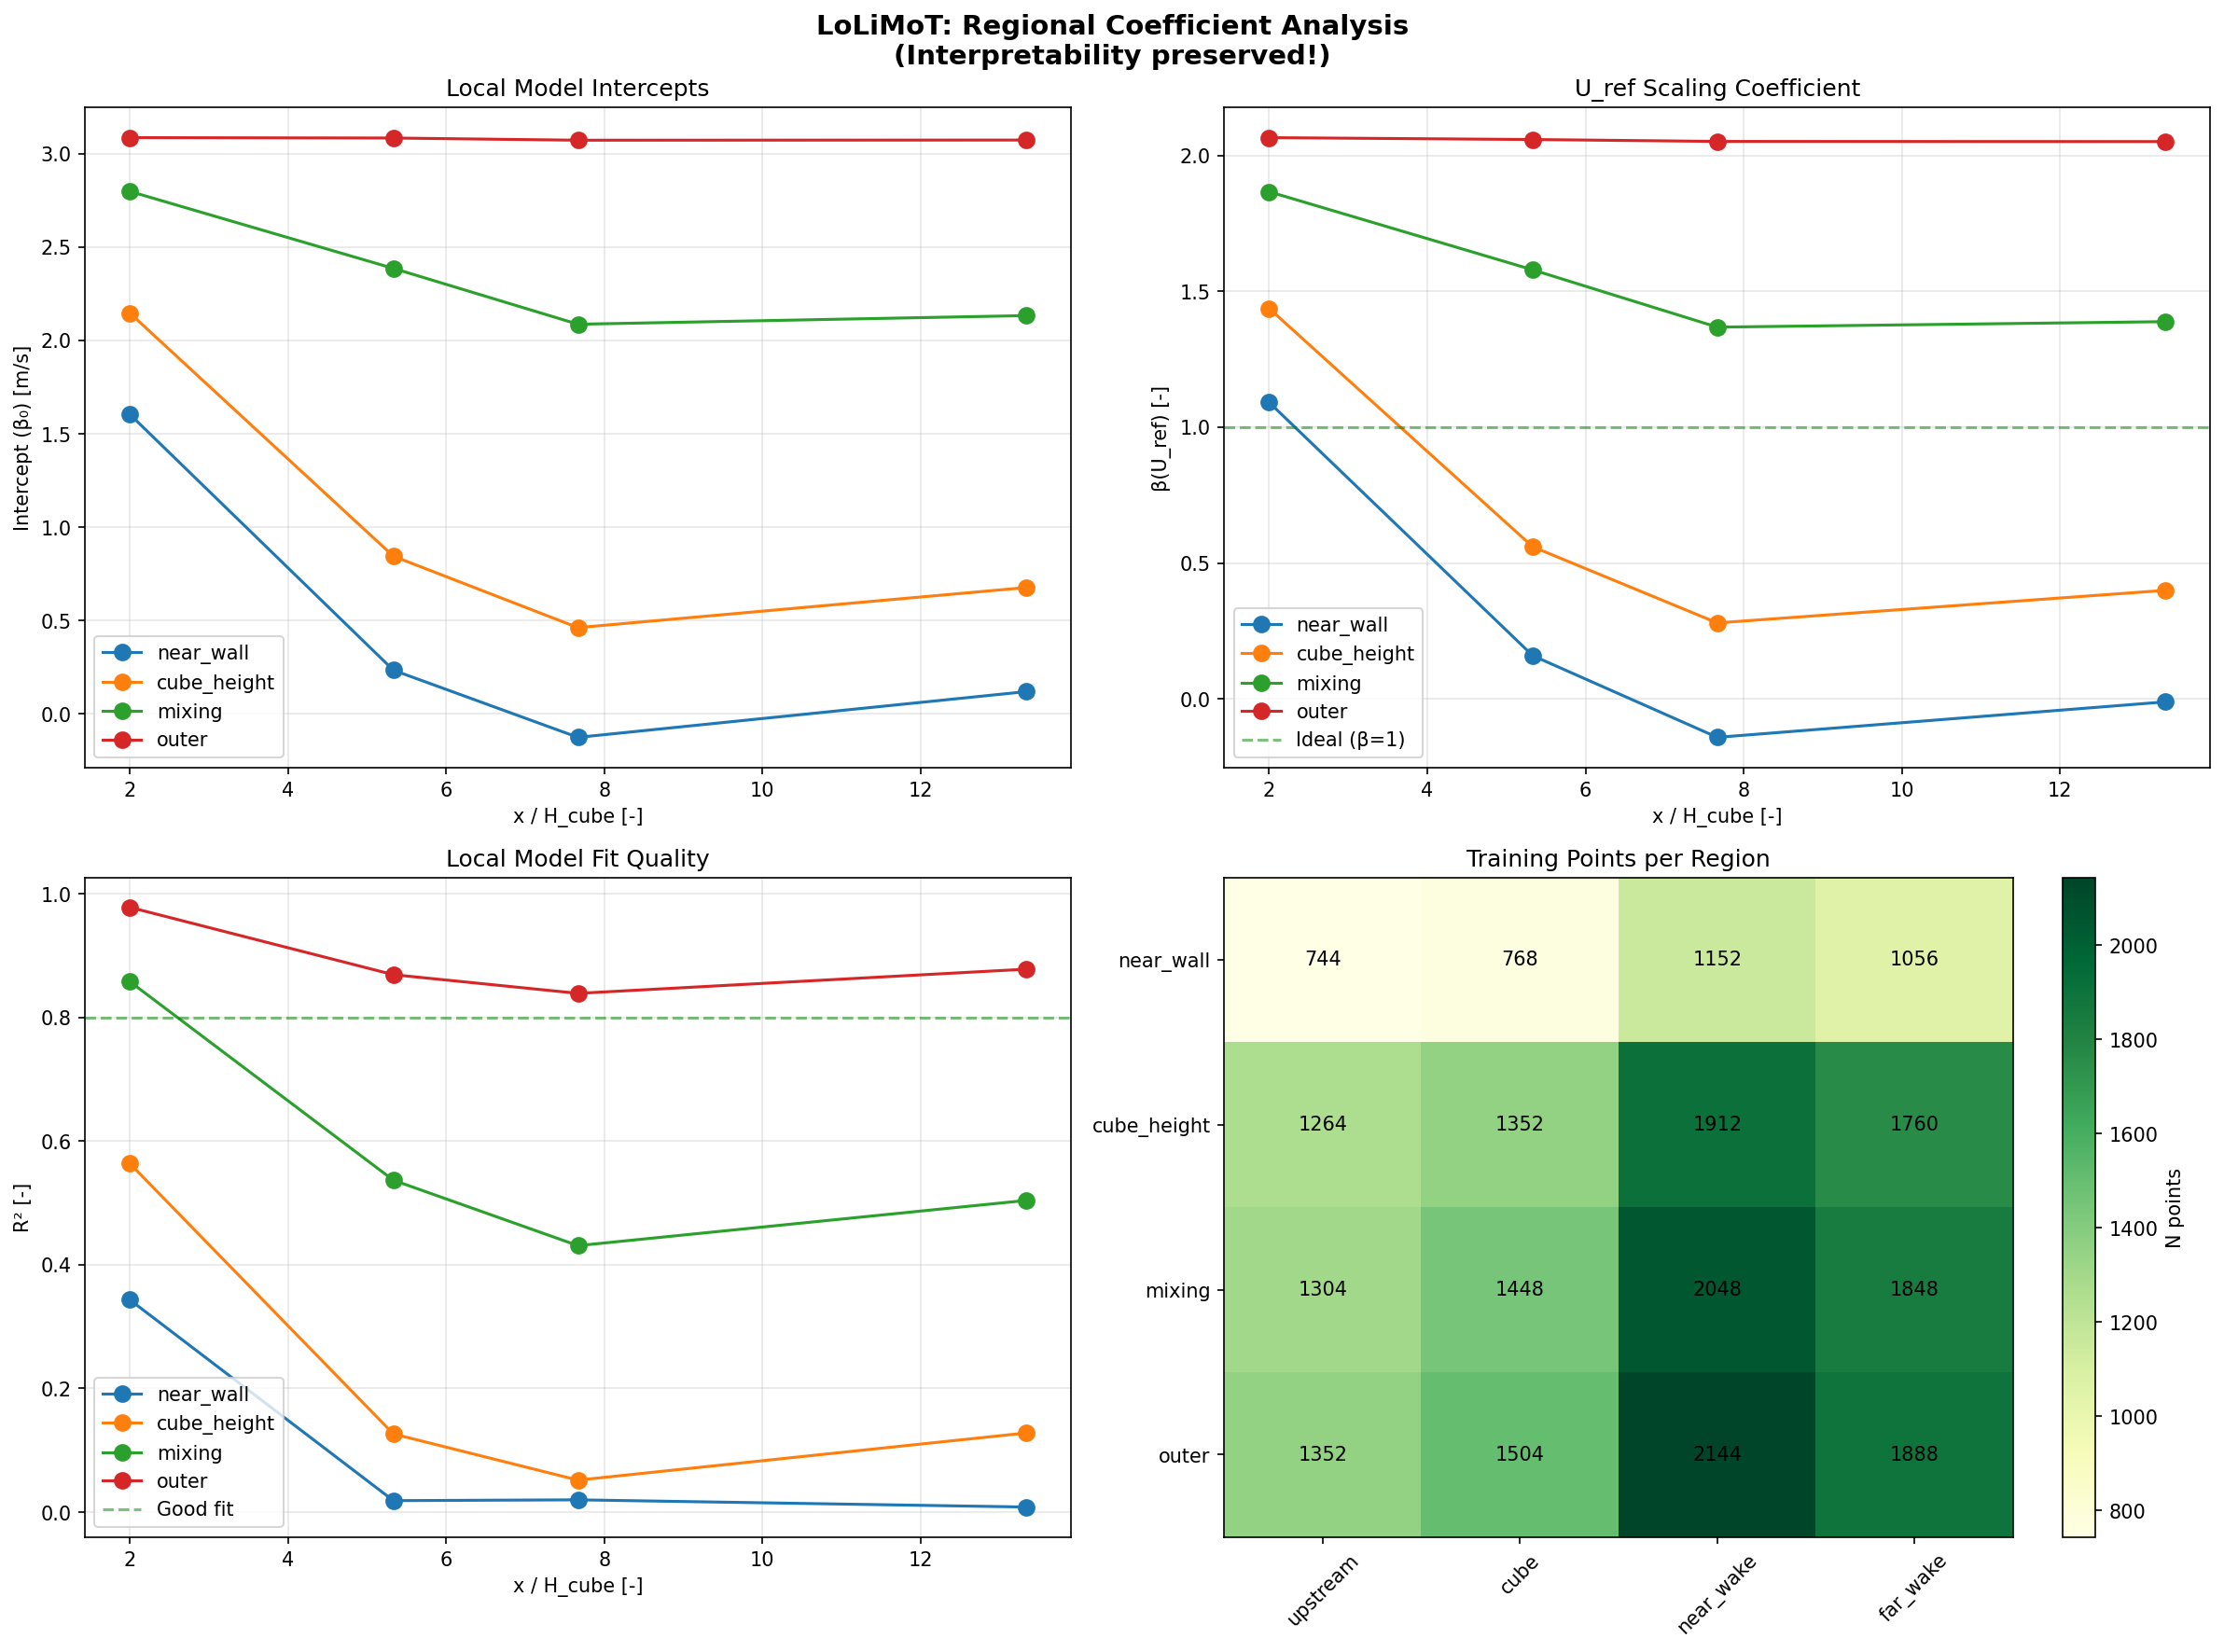

✓ Saved: step5_coefficient_analysis.png


In [23]:
# ============================================================================
# VISUALIZATION 5: COEFFICIENT INTERPRETATION
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Extract coefficients by x-region and z-region
coef_data = []
for region_key, region in REGIONS.items():
    if region_key in region_metrics:
        m = region_metrics[region_key]
        coef_data.append({
            'region': region_key,
            'x_name': region['x_name'],
            'z_name': region['z_name'],
            'x_center': region['x_center'] / H_CUBE,
            'z_center': region['z_center'] / H_CUBE,
            'intercept': m['intercept'],
            'coef_U_ref': m['coef'][0],
            'R2': m['R2'],
            'n_points': m['n_points']
        })

df_coef = pd.DataFrame(coef_data)

# Plot 1: Intercept by region
ax = axes[0, 0]
for z_name in Z_REGIONS.keys():
    subset = df_coef[df_coef['z_name'] == z_name]
    ax.plot(subset['x_center'], subset['intercept'], 'o-', label=z_name, markersize=8)
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('Intercept (β₀) [m/s]')
ax.set_title('Local Model Intercepts')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: U_ref coefficient by region
ax = axes[0, 1]
for z_name in Z_REGIONS.keys():
    subset = df_coef[df_coef['z_name'] == z_name]
    ax.plot(subset['x_center'], subset['coef_U_ref'], 'o-', label=z_name, markersize=8)
ax.axhline(1.0, color='green', linestyle='--', alpha=0.5, label='Ideal (β=1)')
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('β(U_ref) [-]')
ax.set_title('U_ref Scaling Coefficient')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: R² by region
ax = axes[1, 0]
for z_name in Z_REGIONS.keys():
    subset = df_coef[df_coef['z_name'] == z_name]
    ax.plot(subset['x_center'], subset['R2'], 'o-', label=z_name, markersize=8)
ax.axhline(0.8, color='green', linestyle='--', alpha=0.5, label='Good fit')
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('R² [-]')
ax.set_title('Local Model Fit Quality')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: Points per region
ax = axes[1, 1]
x_names = list(X_REGIONS.keys())
z_names = list(Z_REGIONS.keys())
points_matrix = np.zeros((len(z_names), len(x_names)))

for _, row in df_coef.iterrows():
    i = z_names.index(row['z_name'])
    j = x_names.index(row['x_name'])
    points_matrix[i, j] = row['n_points']

im = ax.imshow(points_matrix, cmap='YlGn', aspect='auto')
ax.set_xticks(range(len(x_names)))
ax.set_xticklabels(x_names, rotation=45)
ax.set_yticks(range(len(z_names)))
ax.set_yticklabels(z_names)
ax.set_title('Training Points per Region')
plt.colorbar(im, ax=ax, label='N points')

# Add text
for i in range(len(z_names)):
    for j in range(len(x_names)):
        ax.text(j, i, f'{int(points_matrix[i,j])}', ha='center', va='center')

plt.suptitle('LoLiMoT: Regional Coefficient Analysis\n'
             '(Interpretability preserved!)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step5_coefficient_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step5_coefficient_analysis.png")
plt.close()

In [24]:
# ============================================================================
# SAVE RESULTS
# ============================================================================

print(f"\n{'='*80}")
print("SAVING RESULTS")
print("="*80)

results = {
    'region_models': region_models,
    'region_metrics': region_metrics,
    'regions': REGIONS,
    'X_REGIONS': X_REGIONS,
    'Z_REGIONS': Z_REGIONS,
    'feature_scaler': feature_scaler,
    'onehot_encoder': onehot_encoder,
    'x_train': x_train,
    'x_test': x_test,
    'spatial_results': spatial_results,
    'overall_R2': overall_R2,
    'overall_RMSE': overall_RMSE,
    'H_CUBE': H_CUBE,
    'FEATURE_NAMES': FEATURE_NAMES,
}

with open(RESULTS_OUTPUT, 'wb') as f:
    pickle.dump(results, f)

print(f"✓ Saved: {RESULTS_OUTPUT}")


SAVING RESULTS
✓ Saved: /home/vita/ML/DACI/Multi_Case_CFD/results/reports/step5_lolimot_results.pkl


In [26]:
# ============================================================================
# FINAL SUMMARY
# ============================================================================

print(f"\n{'='*80}")
print("STEP 3C COMPLETE - LoLiMoT SUMMARY")
print("="*80)

print(f"""
🎯 LoLiMoT IMPLEMENTATION:

APPROACH:
  • {len(X_REGIONS)} x-regions × {len(Z_REGIONS)} z-regions = {N_REGIONS} total regions
  • Physics-based partitioning (upstream, cube, wake, far_wake) × (wall, cube_height, mixing, outer)
  • Gaussian validity functions for smooth blending
  • Ridge regression for local linear models

COMPARISON TO INDEPENDENT LOCAL MODELS:
  • Independent models: 165 separate models (one per z-height)
  • LoLiMoT: {N_REGIONS} connected models with smooth transitions
  • Information sharing via overlapping validity functions

SPATIAL TEST RESULTS:
  • Overall R²: {overall_R2:.3f}
  • Overall RMSE: {overall_RMSE:.3f} m/s

INTERPRETABILITY:
  • Each regional model has interpretable coefficients
  • Can analyze how physics changes across regions
  • Validity functions show which regions contribute where

FILES CREATED:
  ✓ step3c_1_region_map.png
  ✓ step3c_2_validity_functions.png
  ✓ step3c_3_profile_predictions.png
  ✓ step3c_4_spatial_test.png
  ✓ step3c_5_coefficient_analysis.png
  ✓ step3c_lolimot_results.pkl
""")

print("="*80)
print("✓ LoLiMoT IMPLEMENTATION COMPLETE")
print("="*80)



STEP 3C COMPLETE - LoLiMoT SUMMARY

🎯 LoLiMoT IMPLEMENTATION:

APPROACH:
  • 4 x-regions × 4 z-regions = 16 total regions
  • Physics-based partitioning (upstream, cube, wake, far_wake) × (wall, cube_height, mixing, outer)
  • Gaussian validity functions for smooth blending
  • Ridge regression for local linear models

COMPARISON TO INDEPENDENT LOCAL MODELS:
  • Independent models: 165 separate models (one per z-height)
  • LoLiMoT: 16 connected models with smooth transitions
  • Information sharing via overlapping validity functions

SPATIAL TEST RESULTS:
  • Overall R²: -0.445
  • Overall RMSE: 0.886 m/s

INTERPRETABILITY:
  • Each regional model has interpretable coefficients
  • Can analyze how physics changes across regions
  • Validity functions show which regions contribute where

FILES CREATED:
  ✓ step3c_1_region_map.png
  ✓ step3c_2_validity_functions.png
  ✓ step3c_3_profile_predictions.png
  ✓ step3c_4_spatial_test.png
  ✓ step3c_5_coefficient_analysis.png
  ✓ step3c_lolim